**Objetivo:** implementar, a partir de uma imagem de satélite com as bandas R, G, B e NIR, um classificador de áreas verdes baseado em regressão logística, treinado pelo método do gradiente com mini-batch e tendo o NDVI como entrada.

## 1. Área de estudo e dados
Utilizou-se uma imagem do satélite Amazonia-1, câmera WFI, com as seguintes características:

- **Produto:** nível 4 (ortorretificado), em números digitais de 10 bits;
- **Data de aquisição:** 18/08/2026, órbita/ponto 035/019;
- **Resolução espacial:** 64 m;
- **Projeção:** UTM, zona 22 Sul, datum WGS84 (EPSG:32722);
- **Recorte:** 904 × 799 pixels (57,9 × 51,1 km), entre as latitudes 22,960° S e 23,439° S e as longitudes 45,540° W e 46,121° W.

A área de estudo abrange os municípios de São José dos Campos, Jacareí, Caçapava e Taubaté, além das represas do Jaguari, de Santa Branca e de Paraibuna. As quatro bandas (azul, verde, vermelho e infravermelho próximo, NIR) foram lidas apenas na área do recorte, e a imagem é apresentada a seguir em cor verdadeira.

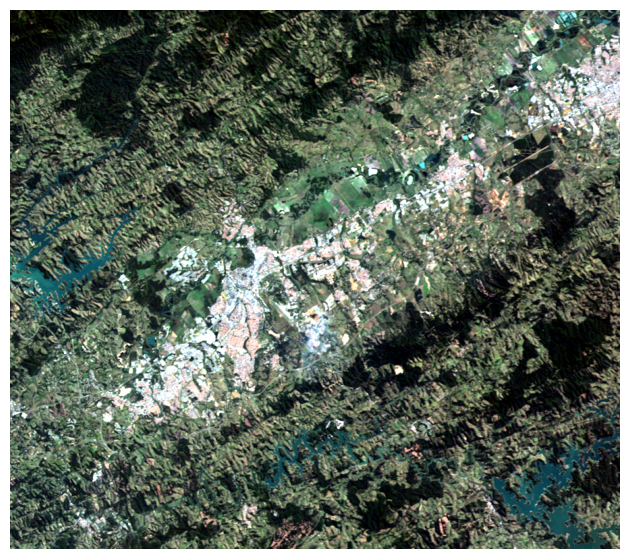

(799, 904)


In [1]:
# Classificação binária (vegetação / não vegetação) com regressão logística, usando o NDVI como entrada

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.windows import Window

# carrega as bandas da imagem AMAZONIA-1/WFI - Level-4-DN: BAND1 = azul, BAND2 = verde, BAND3 = vermelho, BAND4 = NIR
data_path = "data/"
file_name = "AMAZONIA_1_WFI_20260818_035_019_L4_BAND"
window = Window(14104, 5980, 904, 799)  # recorte

def read_band(band):
    with rasterio.open(data_path + file_name + str(band) + ".tif") as src:
        return src.read(1, window=window).astype(float)

blue = read_band(1)
green = read_band(2)
red = read_band(3)
nir = read_band(4)

# exibe a imagem em cor verdadeira
def stretch(band):
    low, high = np.percentile(band, [2, 98])
    return np.clip((band - low) / (high - low), 0, 1)

img = np.dstack([stretch(red), stretch(green), stretch(blue)])
plt.figure(figsize=(8, 7))
plt.imshow(img)
plt.axis("off")
plt.show()
print(red.shape)

## 2. Índice de vegetação por diferença normalizada (NDVI)
O NDVI foi calculado para cada pixel por meio da expressão:

$$NDVI = \frac{NIR - R}{NIR + R}$$

A vegetação absorve a radiação na faixa do vermelho e reflete intensamente no infravermelho próximo, o que resulta em valores elevados de NDVI; áreas urbanas, solo exposto e corpos d'água apresentam valores baixos ou negativos. Como a imagem não foi convertida para reflectância, o índice foi calculado sobre os números digitais, o que desloca os valores para baixo em relação aos de referência da literatura.

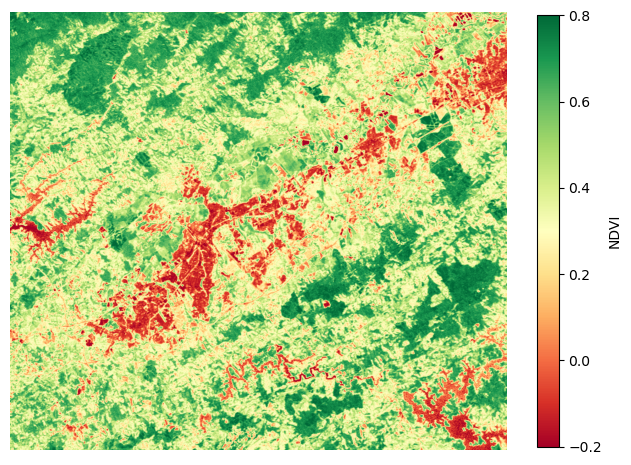

In [2]:
# NDVI = (NIR - R) / (NIR + R), calculado direto sobre os valores das bandas
# (dividir as bandas por uma constante, como na "reflectância simulada" do exemplo, não muda o NDVI)
ndvi = (nir - red) / (nir + red)

plt.figure(figsize=(8, 7))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
plt.axis("off")
plt.colorbar(label="NDVI", shrink=0.8)
plt.show()

## 3. Amostras de treinamento
De forma análoga ao exemplo apresentado em aula, foram selecionados pixels da imagem, rotulados por interpretação visual como vegetação (1) ou não vegetação (0). Como o objetivo é identificar **áreas verdes**, mata, eucalipto, campo e pasto foram considerados vegetação; área urbana, solo exposto e água foram considerados não vegetação.

O conjunto de treinamento contém 40 pixels (20 de cada classe), distribuídos por toda a área de estudo. Foram incluídos também casos de difícil separação, com NDVI próximo da fronteira entre as classes: pasto seco (vegetação) e área urbana com vegetação (não vegetação).

positivo
R = 48   NIR = 255   NDVI = 0.683


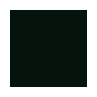

positivo
R = 50   NIR = 296   NDVI = 0.711


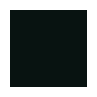

positivo
R = 36   NIR = 286   NDVI = 0.776


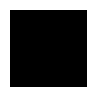

positivo
R = 62   NIR = 269   NDVI = 0.625


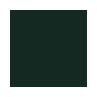

positivo
R = 60   NIR = 340   NDVI = 0.7


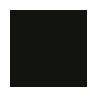

positivo
R = 51   NIR = 399   NDVI = 0.773


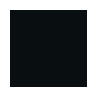

positivo
R = 68   NIR = 352   NDVI = 0.676


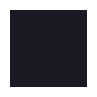

positivo
R = 120   NIR = 408   NDVI = 0.545


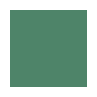

positivo
R = 155   NIR = 424   NDVI = 0.465


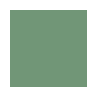

positivo
R = 102   NIR = 386   NDVI = 0.582


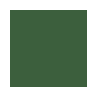

positivo
R = 131   NIR = 258   NDVI = 0.326


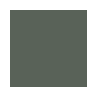

positivo
R = 110   NIR = 293   NDVI = 0.454


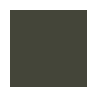

positivo
R = 140   NIR = 279   NDVI = 0.332


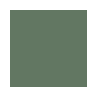

positivo
R = 158   NIR = 309   NDVI = 0.323


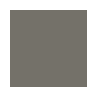

positivo
R = 144   NIR = 288   NDVI = 0.333


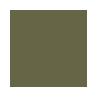

positivo
R = 114   NIR = 282   NDVI = 0.424


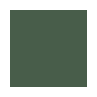

positivo
R = 222   NIR = 297   NDVI = 0.145


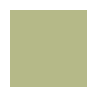

positivo
R = 207   NIR = 275   NDVI = 0.141


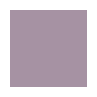

positivo
R = 221   NIR = 333   NDVI = 0.202


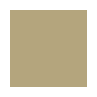

positivo
R = 172   NIR = 286   NDVI = 0.249


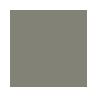

negativo
R = 277   NIR = 230   NDVI = -0.093


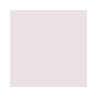

negativo
R = 306   NIR = 234   NDVI = -0.133


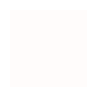

negativo
R = 199   NIR = 193   NDVI = -0.015


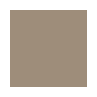

negativo
R = 205   NIR = 179   NDVI = -0.068


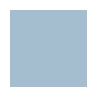

negativo
R = 274   NIR = 236   NDVI = -0.075


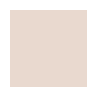

negativo
R = 231   NIR = 207   NDVI = -0.055


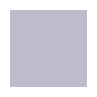

negativo
R = 281   NIR = 229   NDVI = -0.102


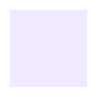

negativo
R = 231   NIR = 297   NDVI = 0.125


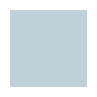

negativo
R = 240   NIR = 314   NDVI = 0.134


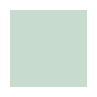

negativo
R = 230   NIR = 302   NDVI = 0.135


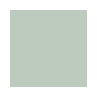

negativo
R = 220   NIR = 280   NDVI = 0.12


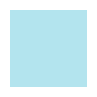

negativo
R = 264   NIR = 320   NDVI = 0.096


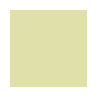

negativo
R = 227   NIR = 284   NDVI = 0.112


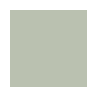

negativo
R = 253   NIR = 317   NDVI = 0.112


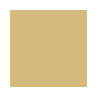

negativo
R = 241   NIR = 293   NDVI = 0.097


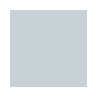

negativo
R = 78   NIR = 42   NDVI = -0.3


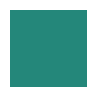

negativo
R = 50   NIR = 58   NDVI = 0.074


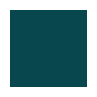

negativo
R = 54   NIR = 59   NDVI = 0.044


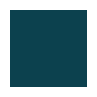

negativo
R = 57   NIR = 53   NDVI = -0.036


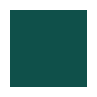

negativo
R = 64   NIR = 49   NDVI = -0.133


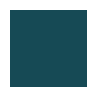

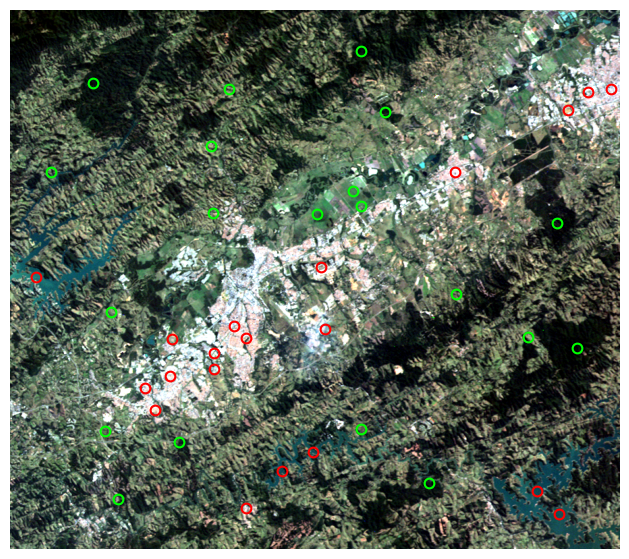

40 pixels de treinamento: 20 de vegetação e 20 de não vegetação


In [3]:
def logistic(ndvi, a, b):
    return 1/(1+np.exp(-(a*ndvi + b)))

# pixels da imagem (linha, coluna, rótulo); 1 = vegetação, 0 = não vegetação
# áreas verdes: mata, eucalipto, campo e pasto são tratados como vegetação
examples = [(107, 122, 1),
            (60, 520, 1),
            (500, 840, 1),
            (640, 250, 1),
            (700, 620, 1),
            (150, 555, 1),
            (315, 810, 1),
            (268, 508, 1),
            (290, 520, 1),
            (302, 455, 1),
            (117, 324, 1),
            (240, 60, 1),
            (300, 300, 1),
            (420, 660, 1),
            (620, 520, 1),
            (623, 141, 1),
            (201, 298, 1),
            (724, 159, 1),
            (484, 768, 1),
            (447, 149, 1),
            (116, 890, 0),
            (239, 659, 0),
            (380, 460, 0),
            (468, 331, 0),
            (542, 237, 0),
            (560, 200, 0),
            (738, 350, 0),
            (472, 466, 0),
            (486, 349, 0),
            (508, 302, 0),
            (531, 302, 0),
            (593, 215, 0),
            (121, 856, 0),
            (147, 826, 0),
            (487, 240, 0),
            (396, 38, 0),
            (683, 403, 0),
            (654, 448, 0),
            (712, 781, 0),
            (747, 813, 0)]

# imprime os exemplos positivos e negativos e mostra a cor de cada pixel
for row, col, label in examples:
    if label == 1:
        print("positivo")
    else:
        print("negativo")
    print("R =", int(red[row, col]), "  NIR =", int(nir[row, col]), "  NDVI =", round(ndvi[row, col], 3))
    pixel = np.array([[img[row, col]]])
    plt.figure(figsize=(1, 1))
    plt.imshow(pixel)
    plt.axis("off")
    plt.show()

# posição dos pixels na imagem (verde = vegetação, vermelho = não vegetação)
plt.figure(figsize=(8, 7))
plt.imshow(img)
plt.axis("off")
for row, col, label in examples:
    plt.plot(col, row, "o", markersize=7, markerfacecolor="none", markeredgewidth=1.5,
             color="lime" if label == 1 else "red")
plt.show()

# pixels de treinamento: x = NDVI do pixel, y = rótulo
x = np.array([ndvi[row, col] for row, col, label in examples])
y = np.array([label for row, col, label in examples])
print(len(x), "pixels de treinamento:", y.sum(), "de vegetação e", len(y) - y.sum(), "de não vegetação")

## 4. Modelo de classificação e treinamento
A probabilidade de um pixel pertencer à classe vegetação é estimada pela função logística:

$$P(\text{vegetação}) = \frac{1}{1 + e^{-(a \cdot NDVI + b)}}$$

em que `a` é o coeficiente associado ao NDVI e `b` é o viés. Os parâmetros foram ajustados por minimização da **entropia cruzada** média, função de perda que mede a discrepância entre as probabilidades estimadas e os rótulos.

Adotou-se o método do gradiente com mini-batch: a cada época, os 40 pixels são embaralhados e divididos em 5 lotes de 8; para cada lote, calcula-se o gradiente médio da perda e atualizam-se `a` e `b` no sentido oposto ao gradiente, com taxa de aprendizado η = 0,5. O treinamento foi executado por 10.000 épocas, o que totaliza 50.000 atualizações.

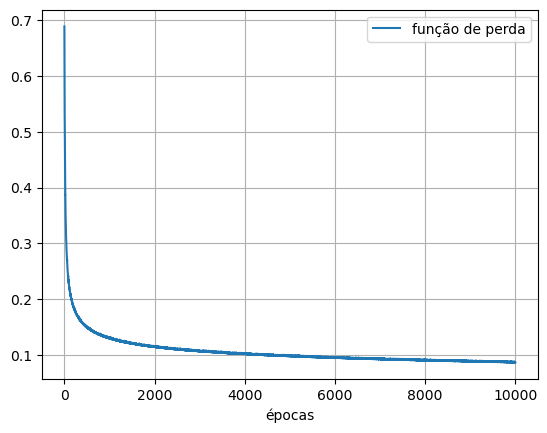

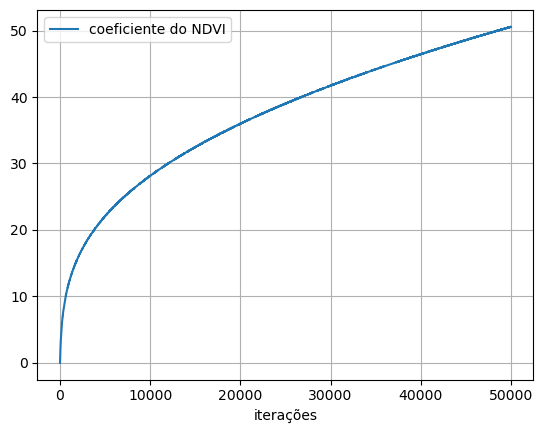

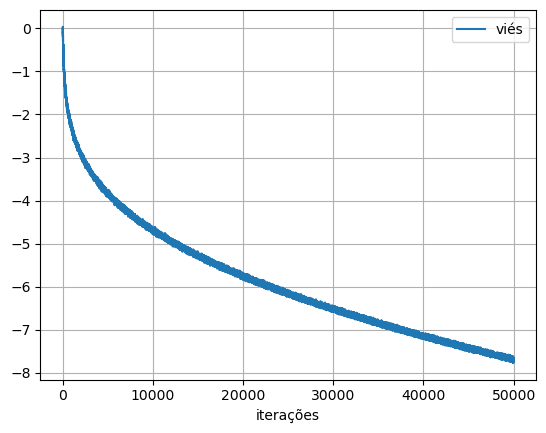

a = 50.57753493931706   b = -7.687255716112921   perda final = 0.08697773499604346
limiar de NDVI aprendido (P = 0,5): NDVI > 0.15198952905348379


In [4]:
# Treinamento do modelo de classificação: método do gradiente com mini-batch
epsilon = 1e-10
N = len(x)
B = 8             # tamanho do mini-batch (40 pixels -> 5 mini-batches por época)
n_epochs = 10000
eta = 0.5
a = 0             # coeficiente do NDVI
a_t = [a]
b = 0             # viés
b_t = [b]
loss = []
np.random.seed(0)
for epoch in range(n_epochs):
    L = 0
    order = np.random.permutation(N)   # embaralha os pixels a cada época
    for k in range(0, N, B):
        batch = order[k:k + B]         # o último mini-batch pode ser menor que B
        y_hat = logistic(x[batch], a, b)
        L = L + np.sum(-y[batch]*np.log(y_hat + epsilon) - (1 - y[batch])*np.log(1 - y_hat + epsilon))
        e = y[batch] - y_hat
        a = a + eta*np.mean(e*x[batch])   # passo contrário ao gradiente médio do mini-batch
        b = b + eta*np.mean(e)
        a_t.append(a)
        b_t.append(b)
    loss.append(L/N)

plt.plot(loss, label="função de perda")
plt.xlabel("épocas")
plt.legend()
plt.grid()
plt.show()

plt.plot(a_t, label="coeficiente do NDVI")
plt.xlabel("iterações")
plt.legend()
plt.grid()
plt.show()

plt.plot(b_t, label="viés")
plt.xlabel("iterações")
plt.legend()
plt.grid()
plt.show()

# função de perda (entropia cruzada média) ao fim do treinamento
y_hat = logistic(x, a, b)
L = np.mean(-y*np.log(y_hat + epsilon) - (1 - y)*np.log(1 - y_hat + epsilon))
print("a =", a, "  b =", b, "  perda final =", L)
print("limiar de NDVI aprendido (P = 0,5): NDVI >", -b/a)

### Resultados do treinamento
Ao final do treinamento, obtiveram-se a = 50,6 e b = −7,7. Um pixel é classificado como vegetação quando P > 0,5, condição equivalente a **NDVI > −b/a = 0,152**. O modelo classificou corretamente 38 dos 40 pixels de treinamento; os dois erros correspondem a pixels de pasto seco com NDVI de 0,141 e 0,145.

Observa-se nos gráficos que os coeficientes não se estabilizam, comportamento também presente no exemplo apresentado em aula. Isso ocorre porque as amostras são quase separáveis por um limiar de NDVI: nessa situação, a perda pode sempre ser reduzida pelo aumento de `a` e `b`. O limiar −b/a, que define a classificação, varia pouco ao longo do treinamento.

## 5. Classificação da imagem
O modelo treinado foi aplicado a todos os pixels do recorte. Na imagem classificada, os pixels em preto correspondem à vegetação (áreas verdes) e os pixels em branco, às demais classes.

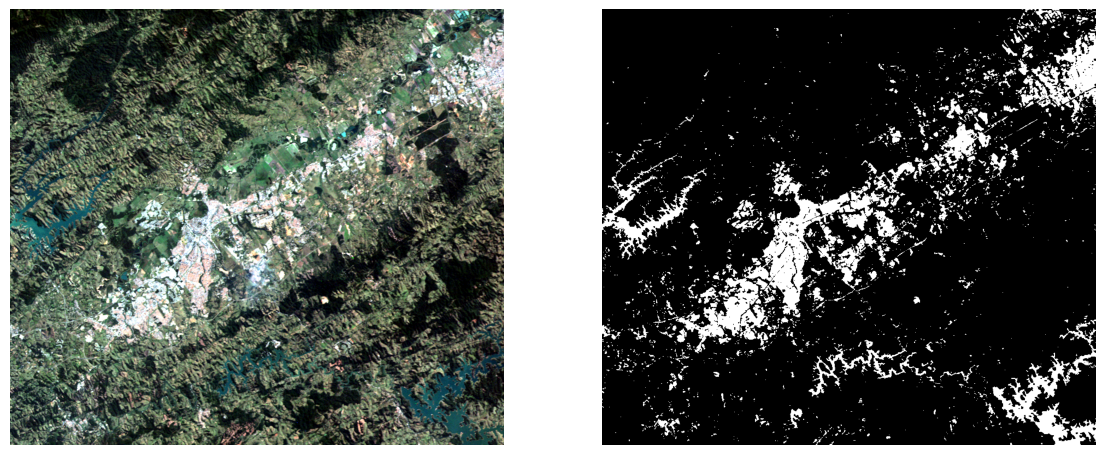

fração da imagem classificada como vegetação: 0.8775972731400977


In [5]:
# Classificação de todos os pixels da imagem
p_veg = logistic(ndvi, a, b)
classified_img = p_veg > 0.5   # preto = vegetação, branco = não vegetação

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(img)
ax[0].axis("off")
ax[1].imshow(classified_img, cmap="gray_r")
ax[1].axis("off")
plt.show()
print("fração da imagem classificada como vegetação:", classified_img.mean())

## 6. Conclusão
Com o NDVI como única variável de entrada, a regressão logística resulta em um limiar de decisão: o pixel é classificado como área verde quando o NDVI é superior a 0,152. Aproximadamente 88% da área de estudo foi classificada como área verde; as regiões não vegetadas correspondem principalmente às manchas urbanas de São José dos Campos, Jacareí, Caçapava e Taubaté e às represas.